## CHC audit note
This notebook retains historical outputs. They are not newly executed CHC results. Use `python -m chc.cli run` and the saved CHC run manifests for current experiments. Code comments explain each step; the MSE2 table reader now handles its actual F1 column instead of assuming a nonexistent Val F1 field.


# Evidence-Guided Detection and Correction of Hallucinations in LLMs (MSE-1)
**Primary Dataset**: RAGTruth (from official GitHub: https://github.com/ParticleMedia/RAGTruth)  

---
## Notebook Flow
1. **Load RAGTruth**
2. **Dataset Inspection**
3. **Preprocessing**
4. **EDA**
5. **Model Identification**

In [1]:
# Learning purpose: Prepare data or inspect the environment for this historical workflow; retain source separation and distinguish printed counts from measured model accuracy.
# ------------------------------------------------------------------------------
# STEP 1: IMPORTS AND SETUP
# ------------------------------------------------------------------------------
import os
from pathlib import Path
# Resolve paths from either the project root or its notebooks directory.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
if not (PROJECT_ROOT / 'src').is_dir():
    raise RuntimeError('Launch this notebook from the project or notebooks directory')
import json
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_RAW = os.path.join(PROJECT_ROOT, 'data', 'raw')
os.makedirs(DATA_RAW, exist_ok=True)
print("Setup ready.")

Setup ready.


In [2]:
# Learning purpose: Prepare data or inspect the environment for this historical workflow; retain source separation and distinguish printed counts from measured model accuracy.
# ------------------------------------------------------------------------------
# STEP 2: LOAD & INSPECT RAGTRUTH DATASET
# ------------------------------------------------------------------------------
resp_file = os.path.join(DATA_RAW, 'response.jsonl')
src_file = os.path.join(DATA_RAW, 'source_info.jsonl')
base_url = 'https://raw.githubusercontent.com/ParticleMedia/RAGTruth/main/dataset/'

# Download raw files if needed
if not os.path.exists(resp_file):
    urllib.request.urlretrieve(base_url + 'response.jsonl', resp_file)
if not os.path.exists(src_file):
    urllib.request.urlretrieve(base_url + 'source_info.jsonl', src_file)

# Load source_info.jsonl into a dictionary
sources = {}
with open(src_file, 'r', encoding='utf-8') as f:
    for line in f:
        item = json.loads(line)
        sources[item['source_id']] = item

# Load response.jsonl and combine with source context
rows = []
with open(resp_file, 'r', encoding='utf-8') as f:
    for line in f:
        item = json.loads(line)
        sid = item['source_id']
        src = sources.get(sid, {})
        task = src.get('task_type', '')
        sinfo = src.get('source_info', '')
        
        # Clean evidence extraction based on task type
        if isinstance(sinfo, str):
            evidence = sinfo
        elif isinstance(sinfo, dict):
            if task == 'QA':
                passages = sinfo.get('passages', '')
                evidence = ' '.join(passages) if isinstance(passages, list) else str(passages)
            elif task == 'Data2txt':
                evidence = '; '.join([f'{k}: {v}' for k, v in sinfo.items()])
            else:
                evidence = str(sinfo)
        else:
            evidence = str(sinfo)
            
        labels = item.get('labels', [])
        types = list(set([span.get('label_type', 'Unknown') for span in labels])) if labels else ['Factual']
        
        rows.append({
            'id': item.get('id'),
            'source_id': sid,
            'task_type': task,
            'prompt': src.get('prompt', ''),
            'evidence': evidence,
            'model': item.get('model', ''),
            'response': item.get('response', ''),
            'split': item.get('split', 'train'),
            'has_hallucination': 1 if len(labels) > 0 else 0,
            'num_hallucination_spans': len(labels),
            'hallucination_types': ', '.join(types),
            'raw_spans': json.dumps(labels)
        })

df = pd.DataFrame(rows)
print(f"Total RAGTruth responses loaded: {len(df)}")
print(f"Official Splits: {dict(df['split'].value_counts())}")
df.head()

Total RAGTruth responses loaded: 17790
Official Splits: {'train': np.int64(15090), 'test': np.int64(2700)}


,id,source_id,task_type,prompt,evidence,model,response,split,has_hallucination,num_hallucination_spans,hallucination_types,raw_spans
0,0,15592,Summary,Summarize the following news within 116 words:...,"Seventy years ago, Anne Frank died of typhus i...",gpt-4-0613,The Anne Frank House has revealed that Anne Fr...,train,0,0,Factual,[]
1,1,15592,Summary,Summarize the following news within 116 words:...,"Seventy years ago, Anne Frank died of typhus i...",gpt-3.5-turbo-0613,New research released by the Anne Frank House ...,train,0,0,Factual,[]
2,2,15592,Summary,Summarize the following news within 116 words:...,"Seventy years ago, Anne Frank died of typhus i...",mistral-7B-instruct,New research conducted by the Anne Frank House...,train,1,3,"Evident Baseless Info, Evident Conflict","[{""start"": 636, ""end"": 653, ""text"": ""February ..."
3,3,15592,Summary,Summarize the following news within 116 words:...,"Seventy years ago, Anne Frank died of typhus i...",llama-2-7b-chat,Here is a summary of the article in 115 words ...,train,1,1,Subtle Baseless Info,"[{""start"": 693, ""end"": 754, ""text"": ""Anne's di..."
4,4,15592,Summary,Summarize the following news within 116 words:...,"Seventy years ago, Anne Frank died of typhus i...",llama-2-13b-chat,"Seventy years ago, Anne Frank died of typhus i...",train,0,0,Factual,[]


In [3]:
# Learning purpose: Prepare data or inspect the environment for this historical workflow; retain source separation and distinguish printed counts from measured model accuracy.
# ------------------------------------------------------------------------------
# STEP 3: PREPROCESSING
# ------------------------------------------------------------------------------
print("Missing values:")
print(df.isnull().sum())

# Clean missing text if any
df['evidence'] = df['evidence'].fillna('')
df['prompt'] = df['prompt'].fillna('')
df['response'] = df['response'].fillna('')

# Filter out empty responses and drop exact duplicates
df_clean = df[df['response'].str.len() > 0].copy()
df_clean = df_clean.drop_duplicates(subset=['prompt', 'response']).copy()

# Calculate word counts for EDA
df_clean['response_word_count'] = df_clean['response'].apply(lambda x: len(str(x).split()))
df_clean['evidence_word_count'] = df_clean['evidence'].apply(lambda x: len(str(x).split()))

print(f"Rows before preprocessing: {len(df)}")
print(f"Rows after preprocessing : {len(df_clean)}")

Missing values:
id                         0
source_id                  0
task_type                  0
prompt                     0
evidence                   0
model                      0
response                   0
split                      0
has_hallucination          0
num_hallucination_spans    0
hallucination_types        0
raw_spans                  0
dtype: int64
Rows before preprocessing: 17790
Rows after preprocessing : 17722


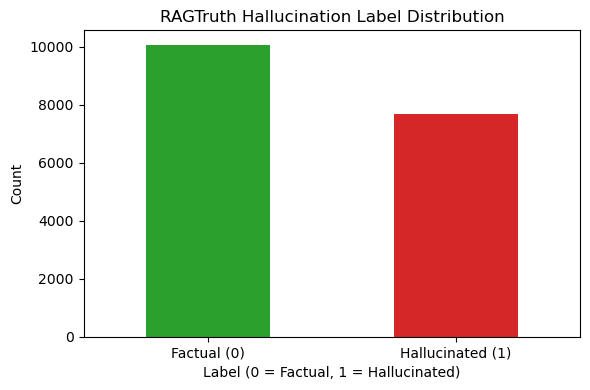

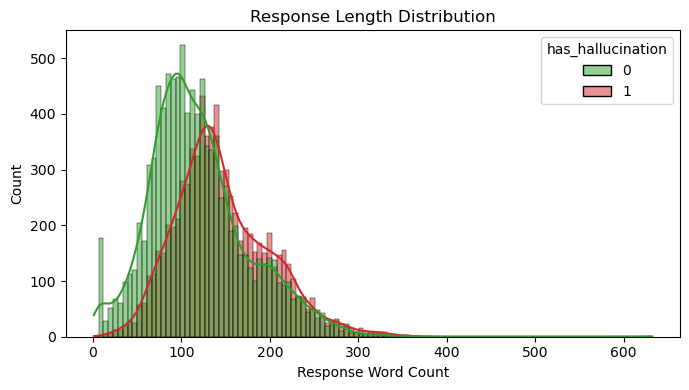

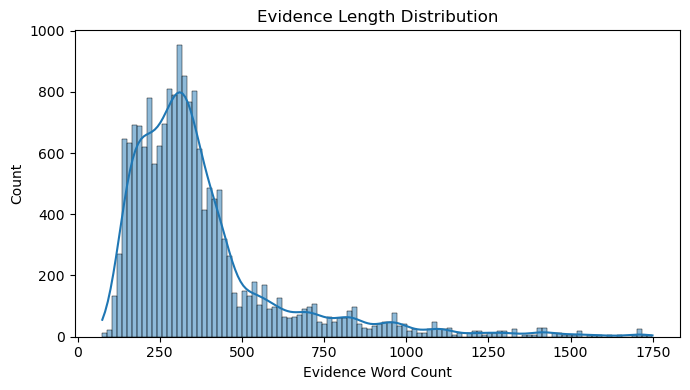

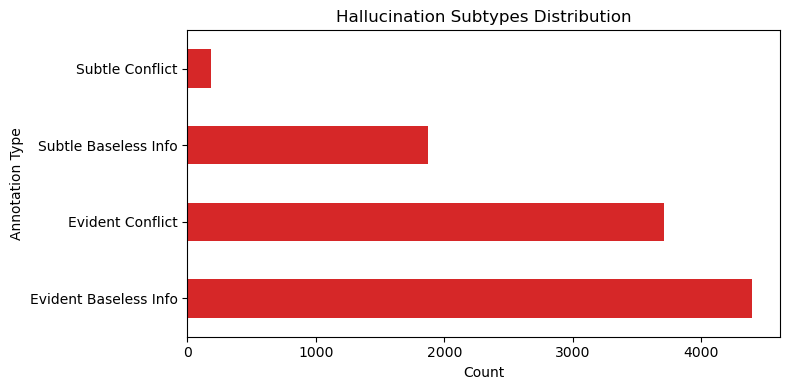

Total responses: 17722
Factual: 10058 | Hallucinated: 7664
Average Response Length: 131.1 words
Average Evidence Length: 379.2 words


In [4]:
# Learning purpose: Prepare data or inspect the environment for this historical workflow; retain source separation and distinguish printed counts from measured model accuracy.
# ------------------------------------------------------------------------------
# STEP 4: EDA (3-4 SIMPLE PLOTS)
# ------------------------------------------------------------------------------
# Graph 1: Hallucination Label Distribution
plt.figure(figsize=(6, 4))
df_clean['has_hallucination'].value_counts().plot(kind='bar', color=['#2ca02c', '#d62728'])
plt.title('RAGTruth Hallucination Label Distribution')
plt.xlabel('Label (0 = Factual, 1 = Hallucinated)')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Factual (0)', 'Hallucinated (1)'], rotation=0)
plt.tight_layout()
plt.show()

# Graph 2: Response Word Length Distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df_clean, x='response_word_count', hue='has_hallucination', kde=True, palette={0: '#2ca02c', 1: '#d62728'})
plt.title('Response Length Distribution')
plt.xlabel('Response Word Count')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Graph 3: Evidence Word Length Distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df_clean, x='evidence_word_count', color='#1f77b4', kde=True)
plt.title('Evidence Length Distribution')
plt.xlabel('Evidence Word Count')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Graph 4: Hallucination Types Distribution
df_hal = df_clean[df_clean['has_hallucination'] == 1]
all_types = []
for t_str in df_hal['hallucination_types']:
    for t in t_str.split(', '):
        if t != 'Factual':
            all_types.append(t)

plt.figure(figsize=(8, 4))
pd.Series(all_types).value_counts().plot(kind='barh', color='#d62728')
plt.title('Hallucination Subtypes Distribution')
plt.xlabel('Count')
plt.ylabel('Annotation Type')
plt.tight_layout()
plt.show()

# Short Numerical Observations
print(f"Total responses: {len(df_clean)}")
print(f"Factual: {(df_clean['has_hallucination']==0).sum()} | Hallucinated: {(df_clean['has_hallucination']==1).sum()}")
print(f"Average Response Length: {df_clean['response_word_count'].mean():.1f} words")
print(f"Average Evidence Length: {df_clean['evidence_word_count'].mean():.1f} words")

## STEP 5: MODEL IDENTIFICATION

For MSE-1, we conceptually compare 3 models (no training is performed):

1. **Baseline**: TF-IDF + Logistic Regression  
   - Input: n-grams of (Prompt + Evidence + Response)  
   - Output: Binary probability of hallucination  
   - Advantages: Fast CPU execution, transparent baseline

2. **Primary Model**: BERT / RoBERTa  
   - Input: `[CLS] Evidence [SEP] Response [SEP]`  
   - Output: Binary classification logits  
   - Advantages: Learns cross-attention between evidence and response

3. **Evidence Verification Model**: DeBERTa-v3 MNLI  
   - Input: Premise = Evidence, Hypothesis = Claim  
   - Output: Entailment / Contradiction classification  
   - Advantages: Directly checks factual entailment against evidence